In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import skimage
print("All libraries imported successfully")
print(f"NumPy version: {np.__version__}")
print(f"scikit-image version: {skimage.__version__}")

All libraries imported successfully
NumPy version: 2.0.2
scikit-image version: 0.24.0


In [2]:
import os

# Define paths
DATA_PATH = "/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/green"

IMAGES_PATH = os.path.join(DATA_PATH, "trainval", "images")
MASKS_PATH = os.path.join(DATA_PATH, "trainval", "ground_truths", "masks")

# Count files
images = sorted(os.listdir(IMAGES_PATH))
masks = sorted(os.listdir(MASKS_PATH))

print(f"Number of images: {len(images)}")
print(f"Number of masks: {len(masks)}")
print(f"\nFirst 5 images: {images[:5]}")
print(f"First 5 masks: {masks[:5]}")

Number of images: 212
Number of masks: 213

First 5 images: ['102.png', '104.png', '106.png', '107.png', '108.png']
First 5 masks: ['102.png', '104.png', '106.png', '107.png', '108.png']


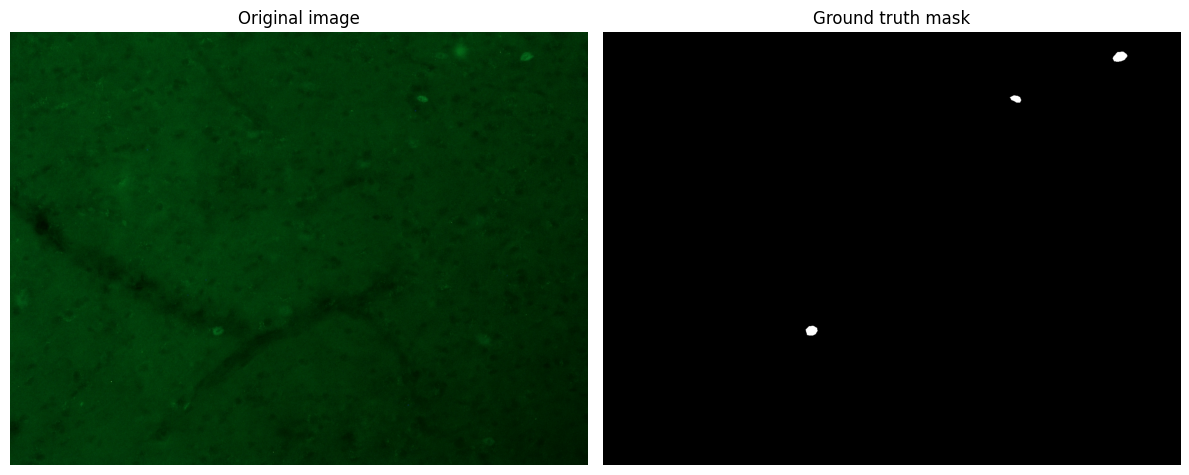

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Load one image and its mask
img = Image.open(os.path.join(IMAGES_PATH, "3.png"))
mask = Image.open(os.path.join(MASKS_PATH, "3.png"))

# Display them side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(img, cmap="gray")
axes[0].set_title("Original image")
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Ground truth mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [4]:
# Convert to numpy arrays to inspect the numbers
img_array = np.array(img)
mask_array = np.array(mask)

print(f"Image shape: {img_array.shape}")
print(f"Image dtype: {img_array.dtype}")
print(f"Image pixel range: {img_array.min()} to {img_array.max()}")

print(f"\nMask shape: {mask_array.shape}")
print(f"Mask dtype: {mask_array.dtype}")
print(f"Mask unique values: {np.unique(mask_array)}")

Image shape: (1200, 1600, 3)
Image dtype: uint8
Image pixel range: 0 to 252

Mask shape: (1200, 1600)
Mask dtype: uint8
Mask unique values: [  0 255]


In [5]:
# Split into RGB channels
r = img_array[:, :, 0]
g = img_array[:, :, 1]
b = img_array[:, :, 2]

print(f"Red channel mean:   {r.mean():.2f}")
print(f"Green channel mean: {g.mean():.2f}")
print(f"Blue channel mean:  {b.mean():.2f}")

Red channel mean:   1.37
Green channel mean: 51.13
Blue channel mean:  7.55


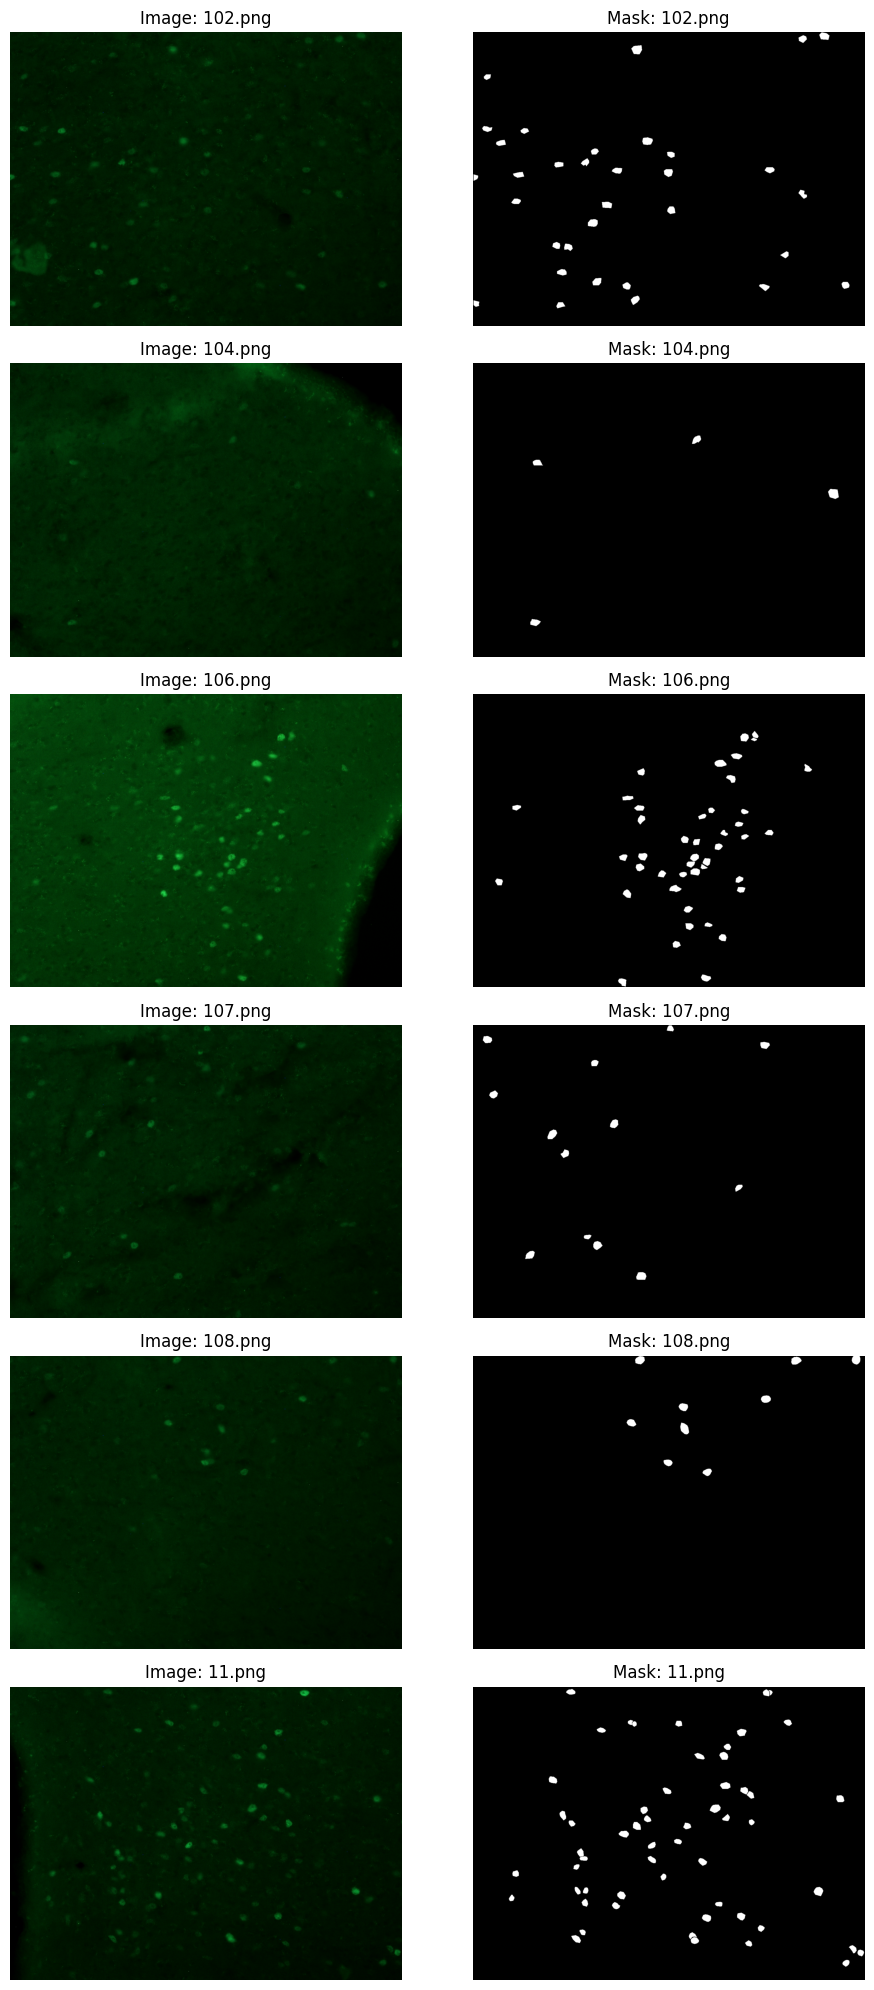

In [6]:
# Display several randomly selected image/mask pairs

sample_names = images[:6]

fig, axes = plt.subplots(len(sample_names), 2, figsize=(10, 20))

for i, filename in enumerate(sample_names):
    img = Image.open(os.path.join(IMAGES_PATH, filename))
    mask = Image.open(os.path.join(MASKS_PATH, filename))

    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"Image: {filename}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title(f"Mask: {filename}")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

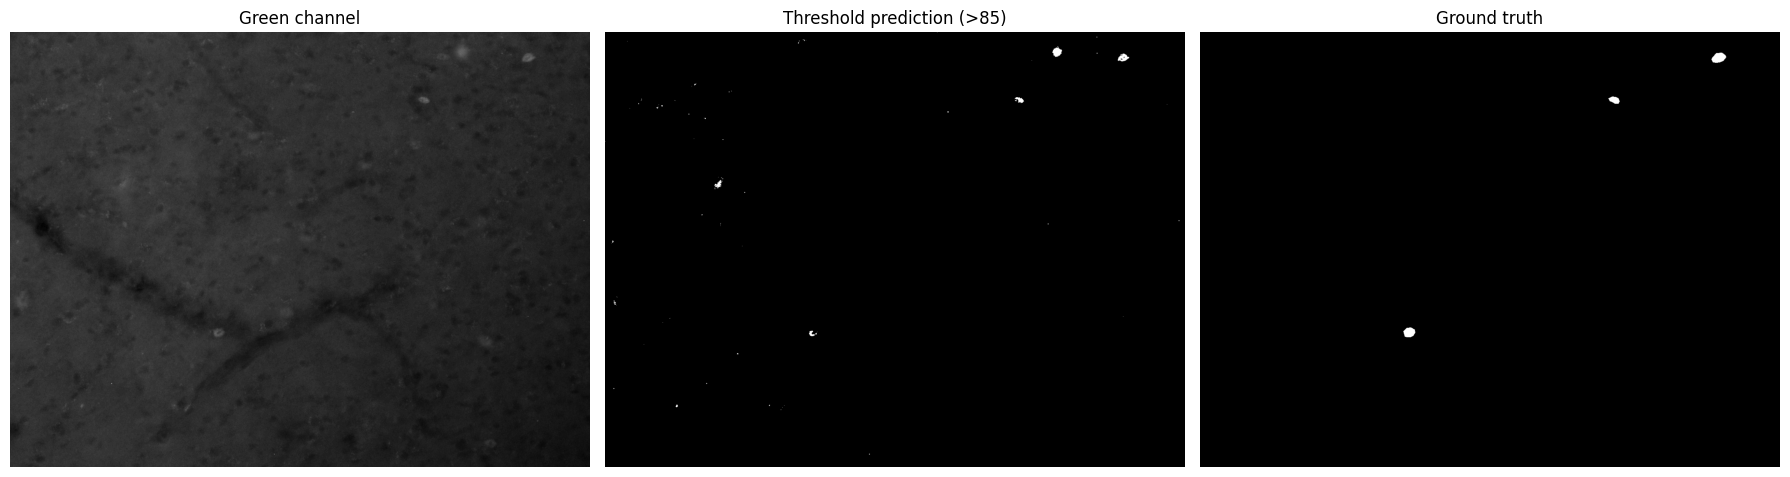

In [16]:
# Work with just the green channel
green = img_array[:, :, 1]

# Apply a simple threshold
threshold = 85
binary = (green > threshold).astype(np.uint8) * 255

# Display original green channel, our prediction, and ground truth
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(green, cmap="gray")
axes[0].set_title("Green channel")
axes[0].axis("off")

axes[1].imshow(binary, cmap="gray")
axes[1].set_title(f"Threshold prediction (>{threshold})")
axes[1].axis("off")

axes[2].imshow(mask_array, cmap="gray")
axes[2].set_title("Ground truth")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [17]:
# Convert mask to binary (0 and 1)
mask_binary = (mask_array > 0).astype(np.uint8)
pred_binary = (binary > 0).astype(np.uint8)

# Calculate basic metrics
tp = np.sum((pred_binary == 1) & (mask_binary == 1))
fp = np.sum((pred_binary == 1) & (mask_binary == 0))
fn = np.sum((pred_binary == 0) & (mask_binary == 1))

precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
dice = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0

print(f"Threshold: 85")
print(f"True Positives:  {tp}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"Dice score: {dice:.3f}")

Threshold: 85
True Positives:  795
False Positives: 981
False Negatives: 1150
Precision: 0.448
Recall:    0.409
Dice score: 0.427


Best threshold: 85
Precision: 0.448
Recall: 0.409
Dice: 0.427


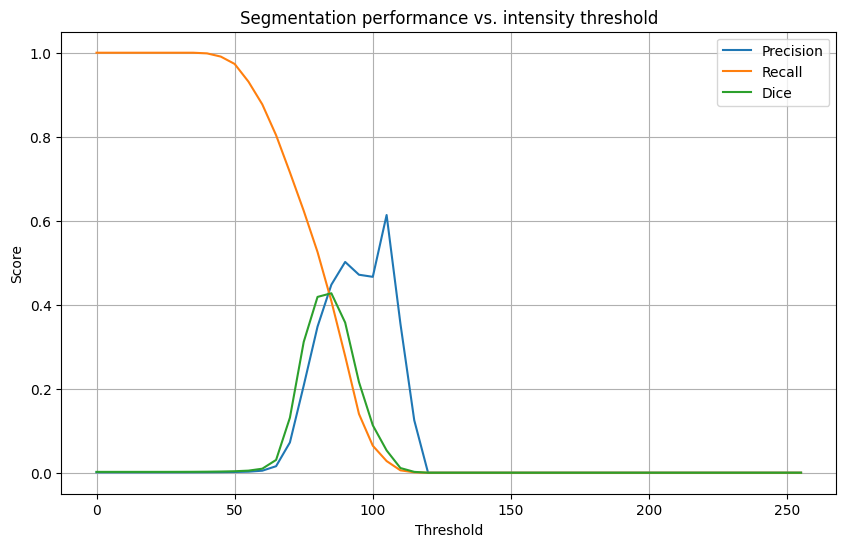

In [15]:
# Test every threshold from 0 to 255 in steps of 5
thresholds = range(0, 256, 5)

# Empty list to store results for each threshold
results = []

# Loop through every threshold value
for threshold in thresholds:
    # Apply threshold to green channel — pixels above threshold = 1, below = 0
    prediction = (green > threshold).astype(np.uint8)

    # Convert ground truth mask to binary 0 and 1
    ground_truth = (mask_array > 0).astype(np.uint8)

    # Count true positives, false positives, false negatives
    tp = np.sum((prediction == 1) & (ground_truth == 1))
    fp = np.sum((prediction == 1) & (ground_truth == 0))
    fn = np.sum((prediction == 0) & (ground_truth == 1))

    # Calculate metrics — if denominator is 0, return 0 to avoid division error
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    dice = (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0

    # Store this threshold's results as a tuple
    results.append((threshold, precision, recall, dice))

# Convert results list to a numpy array for easy indexing
results_array = np.array(results)

# Find the index of the highest Dice score
best_idx = np.argmax(results_array[:, 3])

# Print the best threshold and its metrics
print("Best threshold:", int(results_array[best_idx, 0]))
print("Precision:", round(results_array[best_idx, 1], 3))
print("Recall:", round(results_array[best_idx, 2], 3))
print("Dice:", round(results_array[best_idx, 3], 3))

# Plot precision, recall and dice across all thresholds
plt.figure(figsize=(10, 6))
plt.plot(results_array[:, 0], results_array[:, 1], label="Precision")
plt.plot(results_array[:, 0], results_array[:, 2], label="Recall")
plt.plot(results_array[:, 0], results_array[:, 3], label="Dice")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Segmentation performance vs. intensity threshold")
plt.legend()
plt.grid()
plt.show()

In [18]:
# Evaluate threshold 85 (our best) across all images
all_results = []

for filename in images:
    # Check mask exists for this image
    if filename not in masks:
        continue

    # Load image and mask
    img = Image.open(os.path.join(IMAGES_PATH, filename))
    mask = Image.open(os.path.join(MASKS_PATH, filename))

    # Get green channel
    img_arr = np.array(img)
    mask_arr = np.array(mask)
    green = img_arr[:, :, 1]

    # Apply best threshold
    prediction = (green > 85).astype(np.uint8)
    ground_truth = (mask_arr > 0).astype(np.uint8)

    # Calculate metrics
    tp = np.sum((prediction == 1) & (ground_truth == 1))
    fp = np.sum((prediction == 1) & (ground_truth == 0))
    fn = np.sum((prediction == 0) & (ground_truth == 1))

    dice = (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0
    all_results.append(dice)

print(f"Images evaluated: {len(all_results)}")
print(f"Mean Dice across all images: {np.mean(all_results):.3f}")
print(f"Best Dice:  {np.max(all_results):.3f}")
print(f"Worst Dice: {np.min(all_results):.3f}")

Images evaluated: 212
Mean Dice across all images: 0.219
Best Dice:  0.695
Worst Dice: 0.000


Mean Dice:   0.219
Median Dice: 0.189
Std. Dev.:   0.178
Minimum:     0.000
Maximum:     0.695


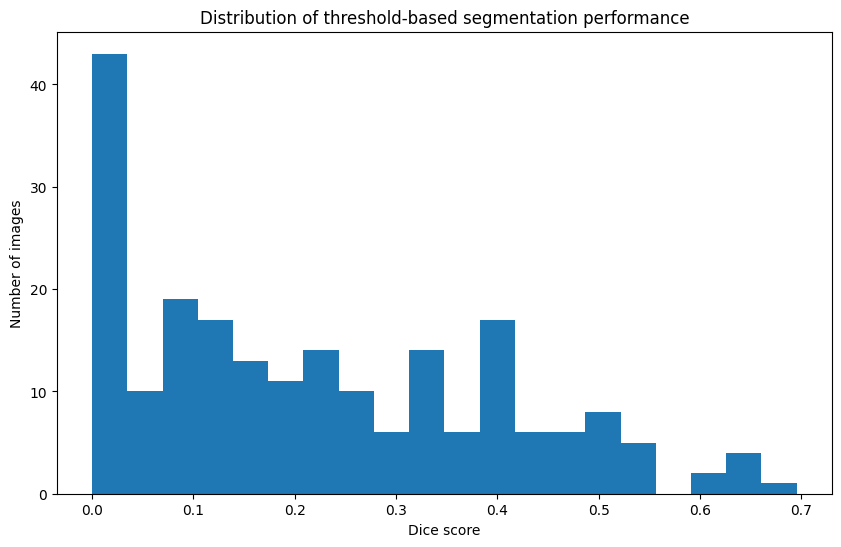

Best image:  106.png (Dice = 0.695)
Worst image: 113.png (Dice = 0.000)


In [19]:
# see how variable the performance actually is.
# Convert our Dice scores into a NumPy array so we can analyse them.
dice_scores = np.array(all_results)

# Calculate some basic statistics describing how performance varies
# across the 212 images.

print(f"Mean Dice:   {dice_scores.mean():.3f}")
print(f"Median Dice: {np.median(dice_scores):.3f}")
print(f"Std. Dev.:   {dice_scores.std():.3f}")
print(f"Minimum:     {dice_scores.min():.3f}")
print(f"Maximum:     {dice_scores.max():.3f}")

# Plot the distribution of Dice scores across the dataset.

# Each bar shows how many images achieved a particular range of Dice scores.
# This lets us see whether our average of 0.219 represents fairly consistent
# performance or a mixture of very good and very poor images.

plt.figure(figsize=(10, 6))

plt.hist(dice_scores, bins=20)

plt.xlabel("Dice score")
plt.ylabel("Number of images")
plt.title("Distribution of threshold-based segmentation performance")

plt.show()

# Find which images produced the best and worst Dice scores.

# np.argmax() gives the position of the highest Dice score.
best_index = np.argmax(dice_scores)

# np.argmin() gives the position of the lowest Dice score.
worst_index = np.argmin(dice_scores)

# Remember that all_results follows the same order as the images we evaluated.
evaluated_images = [
    filename for filename in images
    if filename in masks
]

best_image = evaluated_images[best_index]
worst_image = evaluated_images[worst_index]

print(f"Best image:  {best_image} (Dice = {dice_scores[best_index]:.3f})")
print(f"Worst image: {worst_image} (Dice = {dice_scores[worst_index]:.3f})")

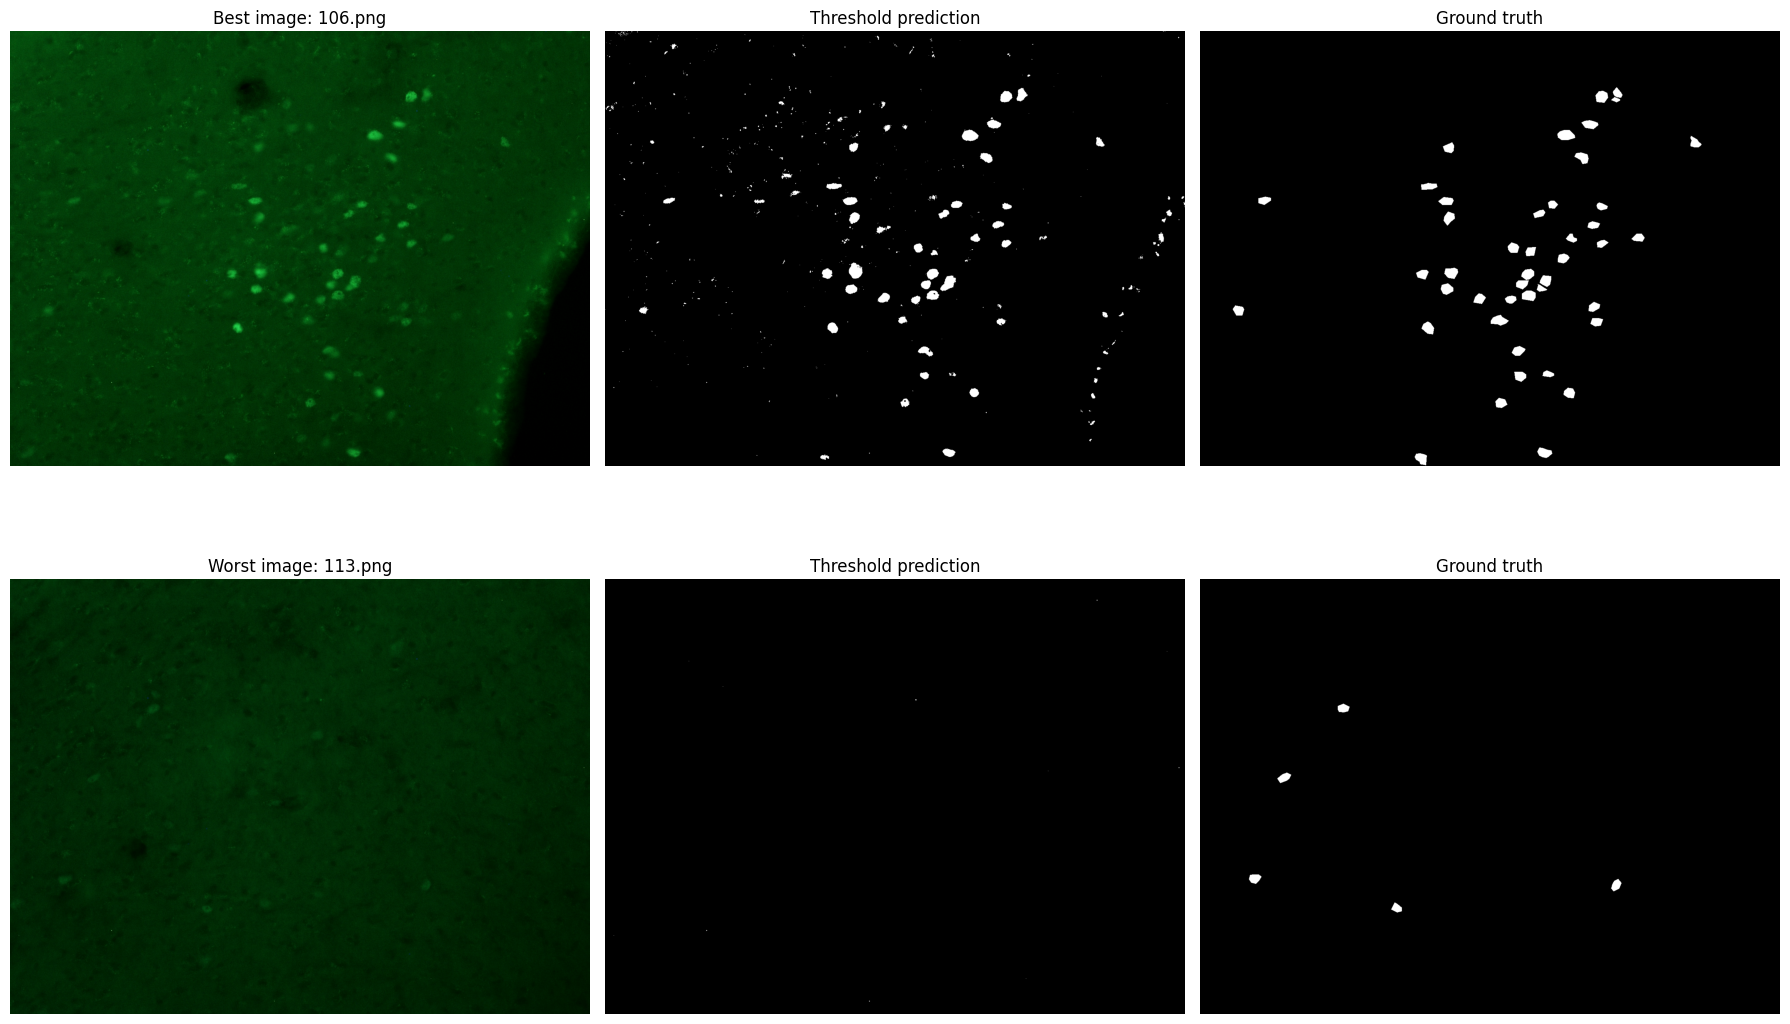

BEST IMAGE
Mean green intensity:   54.09
Median green intensity: 55.00
Maximum green intensity: 253

WORST IMAGE
Mean green intensity:   39.44
Median green intensity: 40.00
Maximum green intensity: 244


In [20]:
# Load the image that our thresholding method performed best on
best_img = Image.open(os.path.join(IMAGES_PATH, best_image))
best_mask = Image.open(os.path.join(MASKS_PATH, best_image))

# Load the image that our thresholding method performed worst on
worst_img = Image.open(os.path.join(IMAGES_PATH, worst_image))
worst_mask = Image.open(os.path.join(MASKS_PATH, worst_image))

# Convert everything into NumPy arrays
best_img_array = np.array(best_img)
best_mask_array = np.array(best_mask)

worst_img_array = np.array(worst_img)
worst_mask_array = np.array(worst_mask)

# Extract the green fluorescence channel from each image
best_green = best_img_array[:, :, 1]
worst_green = worst_img_array[:, :, 1]

# Apply exactly the same threshold to both images
best_prediction = (best_green > 85).astype(np.uint8) * 255
worst_prediction = (worst_green > 85).astype(np.uint8) * 255


# Display the best and worst cases.
#
# This gives us:
#   1. The original fluorescence image
#   2. Our threshold-based prediction
#   3. The ground-truth segmentation
#
# We are looking for visual differences that might explain
# why the exact same algorithm behaves so differently.

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Best image
axes[0, 0].imshow(best_img)
axes[0, 0].set_title(f"Best image: {best_image}")
axes[0, 0].axis("off")

axes[0, 1].imshow(best_prediction, cmap="gray")
axes[0, 1].set_title("Threshold prediction")
axes[0, 1].axis("off")

axes[0, 2].imshow(best_mask_array, cmap="gray")
axes[0, 2].set_title("Ground truth")
axes[0, 2].axis("off")


# Worst image
axes[1, 0].imshow(worst_img)
axes[1, 0].set_title(f"Worst image: {worst_image}")
axes[1, 0].axis("off")

axes[1, 1].imshow(worst_prediction, cmap="gray")
axes[1, 1].set_title("Threshold prediction")
axes[1, 1].axis("off")

axes[1, 2].imshow(worst_mask_array, cmap="gray")
axes[1, 2].set_title("Ground truth")
axes[1, 2].axis("off")

plt.tight_layout()
plt.show()

# Compare the green-channel intensity distributions of the
# best and worst images.
#
# If the images have substantially different intensity distributions,
# this would help explain why a single fixed threshold does not
# generalise well.

print("BEST IMAGE")
print(f"Mean green intensity:   {best_green.mean():.2f}")
print(f"Median green intensity: {np.median(best_green):.2f}")
print(f"Maximum green intensity: {best_green.max()}")

print("\nWORST IMAGE")
print(f"Mean green intensity:   {worst_green.mean():.2f}")
print(f"Median green intensity: {np.median(worst_green):.2f}")
print(f"Maximum green intensity: {worst_green.max()}")

Best dataset-wide threshold: 60
Mean Dice at this threshold: 0.381


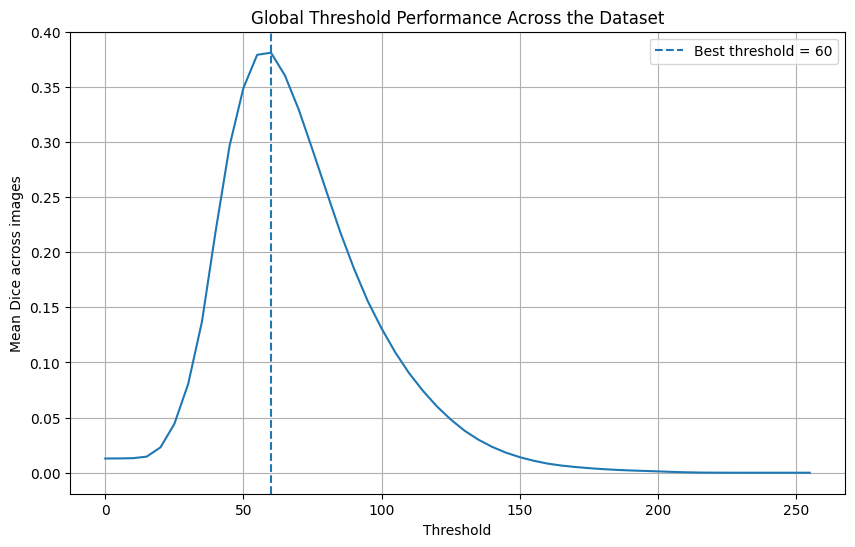

In [21]:
# Find the best threshold across all images
# Store the mean Dice score for every threshold
all_threshold_results = []

# Test thresholds from 0 to 255 in steps of 5
for threshold in range(0, 256, 5):

    # Store the Dice score for every image at this threshold
    dice_scores = []

    # Evaluate this threshold across the whole dataset
    for filename in images:

        # Skip images that do not have a matching ground-truth mask
        if filename not in masks:
            continue

        # Load the image and its corresponding ground-truth mask
        img = Image.open(os.path.join(IMAGES_PATH, filename))
        mask = Image.open(os.path.join(MASKS_PATH, filename))

        # Convert both to NumPy arrays
        img_arr = np.array(img)
        mask_arr = np.array(mask)

        # Use only the green channel because this contains most of the
        # fluorescence signal in our images
        green = img_arr[:, :, 1]

        # Predict neuron pixels using the current threshold
        prediction = (green > threshold).astype(np.uint8)

        # Convert the ground-truth mask into binary form
        ground_truth = (mask_arr > 0).astype(np.uint8)

        # Calculate true positives, false positives and false negatives
        tp = np.sum((prediction == 1) & (ground_truth == 1))
        fp = np.sum((prediction == 1) & (ground_truth == 0))
        fn = np.sum((prediction == 0) & (ground_truth == 1))

        # Calculate Dice score
        denominator = 2 * tp + fp + fn

        if denominator > 0:
            dice = (2 * tp) / denominator
        else:
            dice = 0

        dice_scores.append(dice)

    # Calculate the mean Dice score across all images
    mean_dice = np.mean(dice_scores)

    # Store threshold + mean Dice
    all_threshold_results.append((threshold, mean_dice))


# Convert results into a NumPy array for easier analysis
all_threshold_results = np.array(all_threshold_results)

# Find the threshold with the highest mean Dice score
best_idx = np.argmax(all_threshold_results[:, 1])

best_threshold = int(all_threshold_results[best_idx, 0])
best_mean_dice = all_threshold_results[best_idx, 1]

print(f"Best dataset-wide threshold: {best_threshold}")
print(f"Mean Dice at this threshold: {best_mean_dice:.3f}")


# Plot how performance changes as the threshold changes
plt.figure(figsize=(10, 6))

plt.plot(
    all_threshold_results[:, 0],
    all_threshold_results[:, 1]
)

# Mark the best threshold
plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Best threshold = {best_threshold}"
)

plt.xlabel("Threshold")
plt.ylabel("Mean Dice across images")
plt.title("Global Threshold Performance Across the Dataset")

plt.legend()
plt.grid()

plt.show()

Number of connected components found: 9194


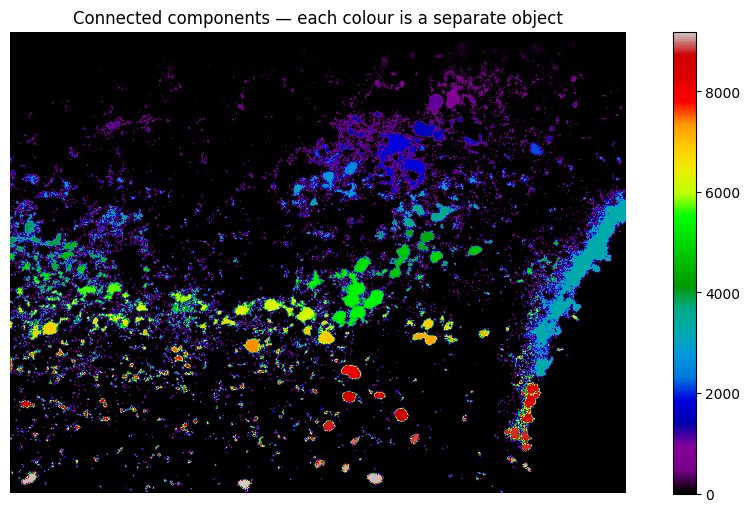

In [22]:
from skimage import measure

# Apply threshold 60 to the green channel of image 106.png
# (our best image — good starting point to see it working)
img = Image.open(os.path.join(IMAGES_PATH, "106.png"))
mask = Image.open(os.path.join(MASKS_PATH, "106.png"))

img_arr = np.array(img)
mask_arr = np.array(mask)
green = img_arr[:, :, 1]

# Apply threshold
binary = (green > 60).astype(np.uint8)

# Label connected components — each separate blob gets a unique integer
labeled = measure.label(binary)

# Count how many objects were found
num_objects = labeled.max()
print(f"Number of connected components found: {num_objects}")

# Display the labeled image
plt.figure(figsize=(12, 6))
plt.imshow(labeled, cmap="nipy_spectral")
plt.title("Connected components — each colour is a separate object")
plt.colorbar()
plt.axis("off")
plt.show()

Total objects: 9194
Smallest object: 1.0 pixels
Largest object: 342083.0 pixels
Median object size: 2.0 pixels
Mean object size: 57.1 pixels


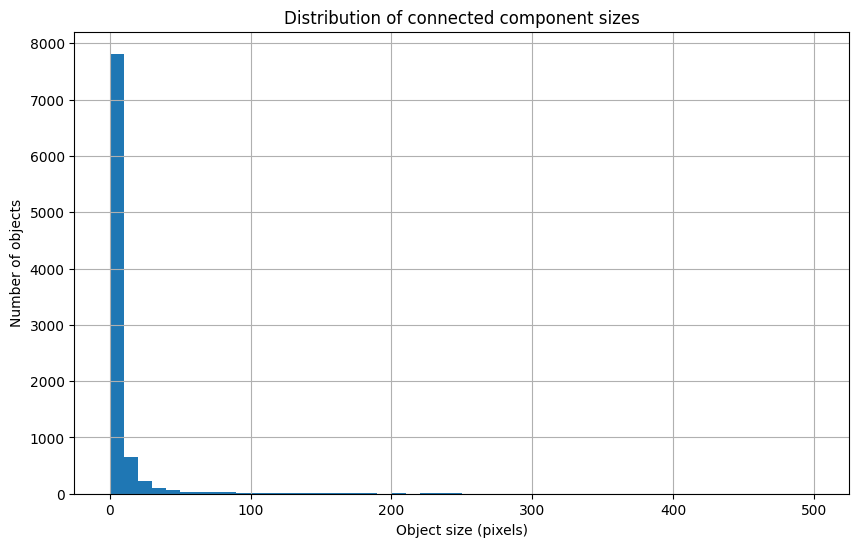

In [23]:
# Get properties of each connected component
regions = measure.regionprops(labeled)

# Extract the area (pixel count) of each object
areas = [region.area for region in regions]
areas = np.array(areas)

print(f"Total objects: {len(areas)}")
print(f"Smallest object: {areas.min()} pixels")
print(f"Largest object: {areas.max()} pixels")
print(f"Median object size: {np.median(areas):.1f} pixels")
print(f"Mean object size: {areas.mean():.1f} pixels")

# Plot the distribution of object sizes
plt.figure(figsize=(10, 6))
plt.hist(areas, bins=50, range=(0, 500))
plt.xlabel("Object size (pixels)")
plt.ylabel("Number of objects")
plt.title("Distribution of connected component sizes")
plt.grid()
plt.show()

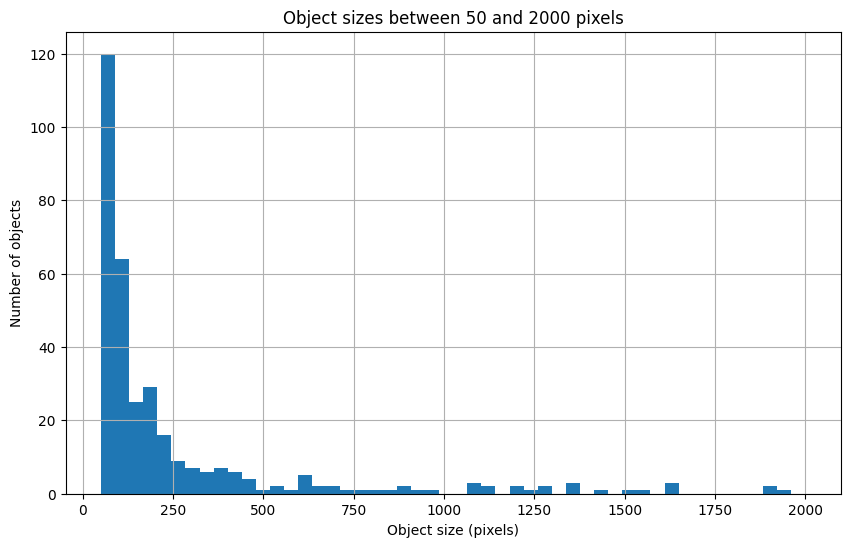

Objects between 50 and 2000 pixels: 336


In [24]:
# Zoom in on objects between 50 and 2000 pixels
# to see where real neurons sit
plt.figure(figsize=(10, 6))
plt.hist(areas, bins=50, range=(50, 2000))
plt.xlabel("Object size (pixels)")
plt.ylabel("Number of objects")
plt.title("Object sizes between 50 and 2000 pixels")
plt.grid()
plt.show()

# How many objects fall in this range?
in_range = np.sum((areas >= 50) & (areas <= 2000))
print(f"Objects between 50 and 2000 pixels: {in_range}")

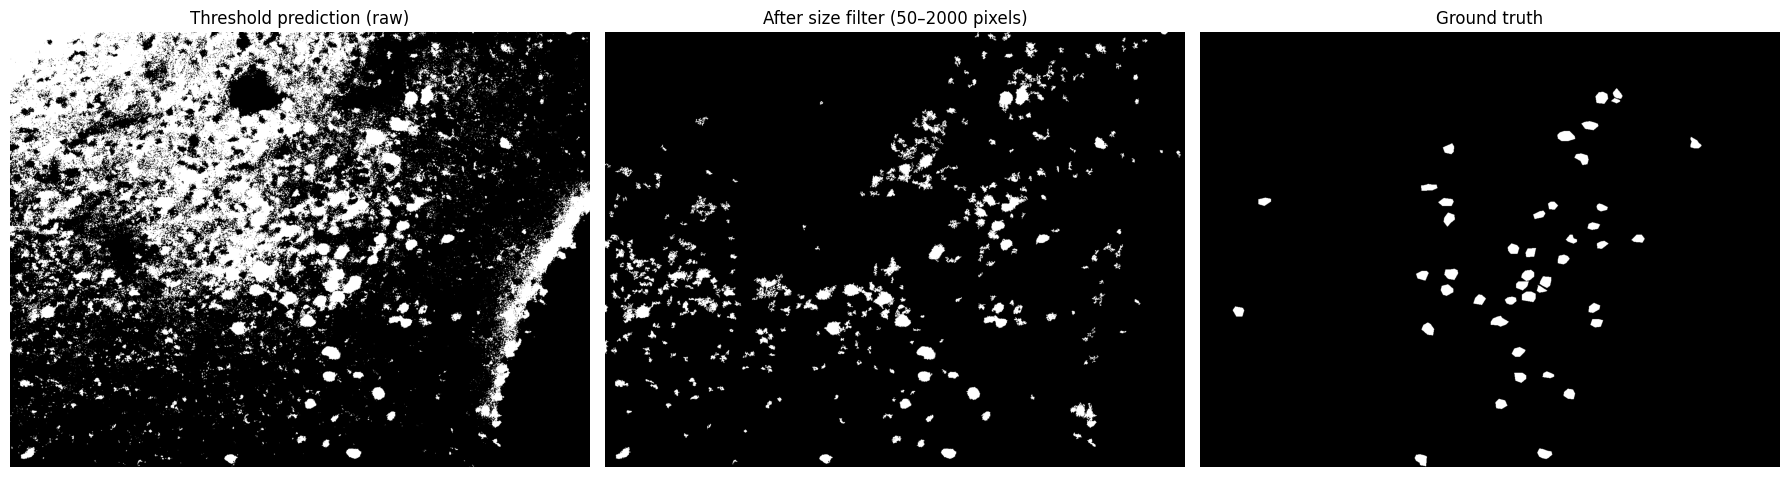

In [25]:
# Create a filtered prediction — keep only objects within our size range
min_size = 50
max_size = 2000

# Build a new binary mask containing only objects in our size range
filtered = np.zeros_like(binary)

for region in regions:
    if min_size <= region.area <= max_size:
        # Set those pixels to 1 in our filtered mask
        for coord in region.coords:
            filtered[coord[0], coord[1]] = 1

# Display original threshold vs filtered vs ground truth
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(binary, cmap="gray")
axes[0].set_title("Threshold prediction (raw)")
axes[0].axis("off")

axes[1].imshow(filtered, cmap="gray")
axes[1].set_title(f"After size filter ({min_size}–{max_size} pixels)")
axes[1].axis("off")

axes[2].imshow(mask_arr, cmap="gray")
axes[2].set_title("Ground truth")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [26]:
# Calculate Dice for raw threshold vs size-filtered prediction
ground_truth = (mask_arr > 0).astype(np.uint8)

# Raw threshold Dice
tp = np.sum((binary == 1) & (ground_truth == 1))
fp = np.sum((binary == 1) & (ground_truth == 0))
fn = np.sum((binary == 0) & (ground_truth == 1))
dice_raw = (2 * tp) / (2 * tp + fp + fn)

# Filtered Dice
tp = np.sum((filtered == 1) & (ground_truth == 1))
fp = np.sum((filtered == 1) & (ground_truth == 0))
fn = np.sum((filtered == 0) & (ground_truth == 1))
dice_filtered = (2 * tp) / (2 * tp + fp + fn)

print(f"Raw threshold Dice (106.png):      {dice_raw:.3f}")
print(f"Size-filtered Dice (106.png):      {dice_filtered:.3f}")

Raw threshold Dice (106.png):      0.100
Size-filtered Dice (106.png):      0.238


In [ ]:
# Evaluate threshold + size filter across all 212 images
filtered_results = []

for filename in images:
    if filename not in masks:
        continue

    img = Image.open(os.path.join(IMAGES_PATH, filename))
    mask = Image.open(os.path.join(MASKS_PATH, filename))

    img_arr = np.array(img)
    mask_arr = np.array(mask)
    green = img_arr[:, :, 1]

    # Apply threshold 60
    binary = (green > 60).astype(np.uint8)

    # Label connected components
    labeled = measure.label(binary)
    regions = measure.regionprops(labeled)

    # Keep only objects between 50 and 2000 pixels
    filtered = np.zeros_like(binary)
    for region in regions:
        if 50 <= region.area <= 2000:
            for coord in region.coords:
                filtered[coord[0], coord[1]] = 1

    # Calculate Dice
    ground_truth = (mask_arr > 0).astype(np.uint8)
    tp = np.sum((filtered == 1) & (ground_truth == 1))
    fp = np.sum((filtered == 1) & (ground_truth == 0))
    fn = np.sum((filtered == 0) & (ground_truth == 1))
    dice = (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0
    filtered_results.append(dice)

print(f"Mean Dice (threshold only):          0.381")
print(f"Mean Dice (threshold + size filter): {np.mean(filtered_results):.3f}")

Mean Dice (threshold only):          0.381
Mean Dice (threshold + size filter): 0.414
